# Sage peptide spectrum matching

Identify which synthetic peptide produced each artificial tandem mass spectrum, using the public Sage search engine.

The FASTA contains short invented peptide standards. A spectrum contains singly charged theoretical b and y ions, small mass errors and unrelated background peaks. Sage builds its fragment index and scores possible peptide-spectrum matches. Known identities give a direct check of identification accuracy.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from tempfile import TemporaryDirectory
from sage_fixture import search

## Run the indexed search

Install the Sage proteomics executable on PATH. The fixture writes its FASTA and mzML into a temporary directory. Telemetry is disabled for this local run.

Known spectra 80
{'Correct': 80, 'Other target': 0, 'Decoy': 0, 'Unreported': 0}
correct fraction of all spectra 1.0


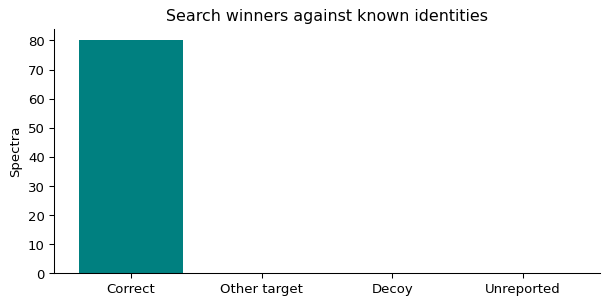

In [2]:
with TemporaryDirectory() as work:
    truth, rows = search(work)
counts = {"Correct": 0, "Other target": 0, "Decoy": 0, "Unreported": len(truth)}
seen = set()
for row in rows:
    scan = row["scannr"]
    assert scan in truth and scan not in seen
    seen.add(scan)
    counts["Unreported"] -= 1
    key = (
        "Decoy"
        if int(row["label"]) < 0
        else "Correct" if row["peptide"] == truth[scan] else "Other target"
    )
    counts[key] += 1
print("Known spectra", len(truth))
print(counts)
print("correct fraction of all spectra", round(counts["Correct"] / len(truth), 3))
assert counts["Correct"] >= 0.9 * len(truth)
fig, ax = plt.subplots(figsize=(6.3, 3.1), constrained_layout=True)
ax.bar(counts.keys(), counts.values(), color=["teal", "sienna", "slategray", "silver"])
ax.set(ylabel="Spectra", title="Search winners against known identities")
plt.show()

## Interpreting the result

Recovery on generated spectra checks software integration and fragment conventions. It does not estimate error rates in a biological sample or test a large production database.

## Exercise

Increase the background peak intensity and compare the proportion identified correctly.

## References

[Lazear, Sage search and quantification (2023)](https://doi.org/10.1021/acs.jproteome.3c00486)

[Sage configuration and inputs](https://sage-docs.vercel.app/docs/configuration)

[OpenMS Python bindings](https://pyopenms.readthedocs.io/)